# AP 155 Lab Exercise
---
## Exercise 12: Integrals

_Instructions_: 
- **Report figure**
    - See Problem 1: Log-log plot of absolute error vs $h$ for trapezoidal and Simpson rules.
- **Report discussion**
    - See Problem 1: Compare and analyze the integration error for both rules. Describe how the methods work and their advantages and disadvantages.
    - See Problem 2: Compare deterministic quadrature with a Monte Carlo estimate. Describe how the methods work and their advantages and disadvantages.
- **Code**: Complete the code and ensure it is functional, error-free, readable, and efficient (where needed). Include concise Markdown documentation highlighting the critical steps of your algorithm for each problem.

### Student Information
- _Full Name (Last Name, First Name)_: Baculo, Ezira Lojelle C.
- _Student No._: 2024-11845
- _Section_: THR-TX-3

### Grading Information (c/o Lab Instructor)
- [Rubrics description link](https://drive.google.com/file/d/1BMSlPot2Mc7XLu0eo4S8I8gLBsIadbCL/view)

| Criteria | Score | Subtotal |
| --- | --- | --- |
| Report figure | XX | 20 |
| Report discussion | XX | 20|
| Code readability | XX | 20 |
| Code efficiency | XX | 20 | 
| Code appropriateness  | XX | 20 | 
| **TOTAL** | XXX | 100 |

_Date and Time Scored (MM/DD/YYYY HH:MM AM/PM):_ 

---
## Section 1: Report

### Report Figure

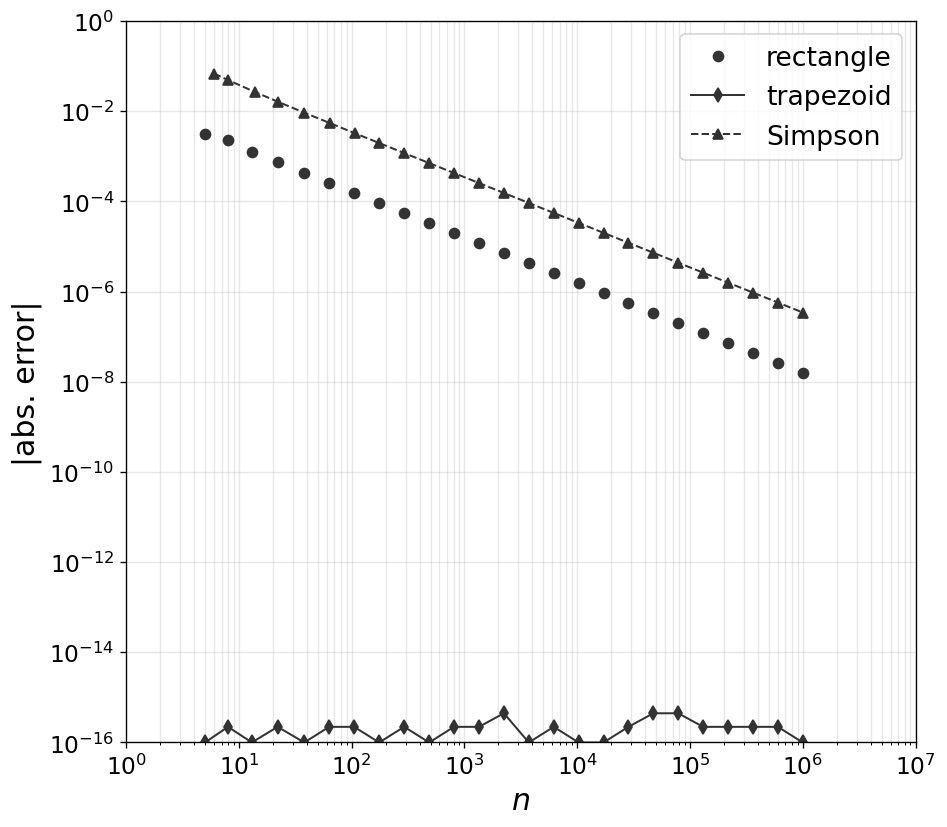

In [12]:
fig1

**Figure 1.** Log-log plot of the absolute error against step size $h$. It compares the absolute error of the rectangle, trapezoid, and Simpson's rules in evaluating the dimensionless period ratio $T/T_0$ of a nonlinear pendulum ($\theta_0 = 0.5\text{ rad}$) on the interval $[0, \pi/2]$ based on the step size $h = \frac{b-a}{n-1}$. As the number of subgrid points $n$ increases on a log-log scale, these demonstrate the theoretical convergence rates: $\mathcal{O}(h)$ for the rectangle method, $\mathcal{O}(h^2)$ for the trapezoidal method, and $\mathcal{O}(h^4)$ for Simpson's method.



### Report discussion

*(1) Compare and analyze the integration error for both rules. Describe how the methods work and their advantages and disadvantages.*
- Comparison and Analysis:
  - Rectangle Rule: Approximates the integral by evaluating the function at the left/right endpoints of subintervals, treating the integrand as a piecewise constant function. Its overall error scales as $\mathcal{O}(h)$, resulting in low computational efficiency for high accuracy.
  - Trapezoidal Rule: Fits linear interpolants between consecutive grid points, approximating the area under the curve as trapezoids. Its overall error scales at $\mathcal{O}(h^2)$, providing significantly faster error reduction compared to the rectangle rule.
  - Simpson's Rule: Applies quadratic polynomials over pairs of subintervals (requiring an even number of subintervals/odd number of points). Its overall error scales at $\mathcal{O}(h^4)$, yielding high-order accuracy with a relatively small number of grid points.
<br>
- Advantages and Disadvantages:
  - Trapezoidal Rule: Advantage: Easy to apply, works for any arbitrary number of grid points $n$. Disadvantage: Lower accuracy order ($\mathcal{O}(h^2)$) compared to Simpson's rule.
  - Simpson's Rule: Advantage: Extremely fast convergence rate ($\mathcal{O}(h^4)$), reaching machine precision quickly. Disadvantage: Needs an even number of subintervals (odd $n$), limiting flexibility with random unstructured grids.

*(2) Compare deterministic quadrature with a Monte Carlo estimate. Describe how the methods work and their advantages and disadvantages.*
- Comparison and Analysis:
  - Deterministic Quadrature (Tensor-Product Grids): Evaluates the integrand across a structured, evenly spaced grid of points across all $d$ dimensions. The total number of evaluations scales exponentially as $\mathcal{O}(N_1^d)$, where $N_1$ represents the number of points in each dimension.
  - Monte Carlo Quadrature: Estimates the integral stochastically by sampling $N$ uniform random points within the bounding domain $\Omega = [-1, 1]^d$ and computing the average of the indicator function $f(\mathbf{x})$. The statistical error decreases in accordance to the central limit theorem as $\mathcal{O}(N^{-1/2})$, regardless of dimension $d$.
<br>
- Advantages and Disadvantages:
  - Deterministic Quadrature: Advantage: Highly accurate and consistent for low-dimensional integrals ($d \le 3$). Disadvantage: Experience significant issues from the curse of dimensionality. For $d = 8$, a simple grid of 10 points per dimension needs $10^8$ function evaluations, making it computationally unmanageable.
  - Monte Carlo Quadrature: Advantage: Immune to the curse of dimensionality. Integration error converges at $\mathcal{O}(N^{-1/2})$ regardless of whether $d = 2$ or $d = 8$. Disadvantage: The slow stochastic convergence rate requires millions of samples for high accuracy, and results contain inherent statistical variance between runs.

### Other comments
- Wala naman po akong other comments.
- Konti na lang at patapos na ang sem (finally) T^T.
- 😭😭😭

#### Disclosure of AI Use:

I acknowledge the use of Gemini (accessed November 2026) to generate a first draft of the algorithms. All AI-assisted suggestions were reviewed and revised with the help of the references provided in the lecture and researched to ensure accuracy and clarity of meaning.

---
## Section 2: Code

In [1]:
import numpy as np
import matplotlib.pyplot as plt
import math

### Problem 0: Testing with an easy integral

Test the rectangle, trapezoidal, Simpson's rule, and Monte Carlo quadrature on an easy function first. Analytically solve the integral below and test whether the modular functions work.
$$ \int_0^\pi \sin(x)dx \tag{1}.$$

In [17]:
"""
Analytical solution:
\int_0^\pi \sin(x) dx = [-cos(x)]_0^\pi = -cos(\pi) - (-cos(0)) = 1 - (-1) = 2
"""

# Define the modular functions directly to ensure they are defined in this execution environment
def rectangle(f, a, b, n):
    h = (b - a) / (n - 1)
    xs = a + np.arange(n - 1) * h
    fs = f(xs)
    return h * np.sum(fs)

def trapezoid(f, a, b, n):
    h = (b - a) / (n - 1)
    xs = a + np.arange(n) * h
    cs = np.ones(n)
    cs[0] = 0.5
    cs[-1] = 0.5
    contribs = cs * f(xs)
    return h * np.sum(contribs)

def simpson(f, a, b, n):
    h = (b - a) / (n - 1)
    xs = a + np.arange(n) * h
    cs = 2 * np.ones(n)
    cs[1::2] = 4
    cs[0] = 1
    cs[-1] = 1
    contribs = cs * f(xs)
    return (h / 3) * np.sum(contribs)

def stats(fs):
    n = fs.size
    fbar = np.sum(fs) / n
    fsq = np.sum(fs**2) / n
    varfbar = (fsq - fbar**2) / (n - 1)
    return fbar, np.sqrt(varfbar)

def montecarlo(f, a, b, n, option="uniform"):
    np.random.seed(314159)
    us = np.random.uniform(a, b, n)
    if option == "uniform":
        fs = f(us)
    else:
        c0 = 4 - 2 * np.sqrt(2)
        c1 = -6 + 4 * np.sqrt(2)
        xs = (-c0 + np.sqrt(2 * c1 * us + c0**2)) / c1
        fs = f(xs) / (c0 + c1 * xs)
    fbar, err = stats(fs)
    return (b - a) * fbar, (b - a) * err

def test_integrand(x):
    return np.sin(x)

a, b = 0.0, np.pi
n_points = 1000
exact_value = 2.0

# Evaluate using the modular functions
val_rect = rectangle(test_integrand, a, b, n_points)
val_trap = trapezoid(test_integrand, a, b, n_points)
val_simp = simpson(test_integrand, a, b, n_points)
val_mc, err_mc = montecarlo(test_integrand, a, b, n_points)

print(f"Analytical Value: {exact_value}")
print(f"Rectangle Rule:   {val_rect:.6f} (Error: {abs(val_rect - exact_value):.2e})")
print(f"Trapezoidal Rule: {val_trap:.6f} (Error: {abs(val_trap - exact_value):.2e})")
print(f"Simpson's Rule:   {val_simp:.6f} (Error: {abs(val_simp - exact_value):.2e})")
print(f"Monte Carlo:      {val_mc:.6f} (Error: {abs(val_mc - exact_value):.2e}, Est. Stat Error: {err_mc:.2e})")

Analytical Value: 2.0
Rectangle Rule:   1.999998 (Error: 1.65e-06)
Trapezoidal Rule: 1.999998 (Error: 1.65e-06)
Simpson's Rule:   1.999998 (Error: 1.65e-06)
Monte Carlo:      1.946689 (Error: 5.33e-02, Est. Stat Error: 3.07e-02)


### Problem 1: Newton-Cotes quadrature and error scaling in nonlinear pendulum oscillations

For small angular displacements, a simple pendulum executes simple harmonic motion with a period 
$$T_0 = 2\pi\sqrt{L/g}. $$
However, for large initial angular amplitudes $\theta_0$, the exact period requires solving an incomplete elliptic integral of the first kind:
$$T(\theta_0) = 4 \sqrt{\frac{L}{g}} \int_{0}^{\pi/2} \frac{d\phi}{\sqrt{1 - k^2 \sin^2\phi}}$$
where $k = \sin\left(\frac{\theta_0}{2}\right)$. 

You will evaluate the dimensionless period ratio 
$$\frac{T}{T_0} = \frac{2}{\pi} \int_{0}^{\pi/2} \frac{d\phi}{\sqrt{1 - k^2 \sin^2\phi}}\tag{2}$$ using composite Newton-Cotes integration techniques.

Use the modular functions in Section 3, solve Eq. $(2)$ given $\theta_0=0.5\;\text{rad}$, $[a,b]=[0, \pi/2]$ using both the trapezoidal rule and Simpson's rule.

**REPORT FIGURE 1**
- Create a log-log plot resulting from the rectangle, trapezoid, and Simpson’s rules of evaluation of Eq. (3). For the absolute error use the `scipy` as the benchmark, i.e. absolute error$=|x_\text{integrated} - x_\text{scipy}|$.

**REPORT DISCUSSION 1**
- Differentiate the two methods and explain what the log-log error plot implies

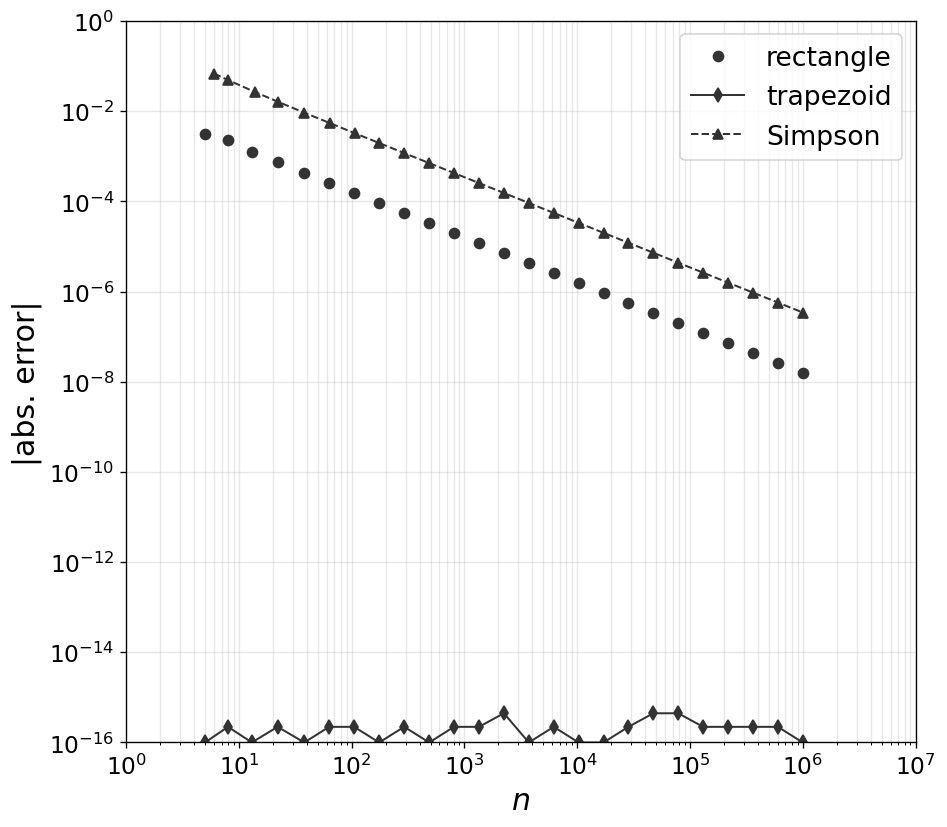

In [11]:
import numpy as np
import matplotlib.pyplot as plt
from scipy.integrate import quad

# Newton-Cotes Quadrature Implementations

def rectangle(f, a, b, n):
    h = (b - a) / (n - 1)
    xs = a + np.arange(n - 1) * h
    fs = f(xs)
    return h * np.sum(fs)

def trapezoid(f, a, b, n):
    h = (b - a) / (n - 1)
    xs = a + np.arange(n) * h
    cs = np.ones(n)
    cs[0] = 0.5
    cs[-1] = 0.5
    contribs = cs * f(xs)
    return h * np.sum(contribs)

def simpson(f, a, b, n):
    h = (b - a) / (n - 1)
    xs = a + np.arange(n) * h
    cs = 2 * np.ones(n)
    cs[1::2] = 4
    cs[0] = 1
    cs[-1] = 1
    contribs = cs * f(xs)
    return (h / 3) * np.sum(contribs)

theta_0 = 0.5  # Initial angular amplitude in radians
k = np.sin(theta_0 / 2.0)

def integrand(x):
    return 1.0 / np.sqrt(1.0 - k**2 * np.sin(x)**2)

a, b = 0.0, np.pi / 2.0

# Compute exact benchmark using SciPy's quad and multiply by 2/pi for T/T_0
integral_val, _ = quad(integrand, a, b)
exact_integral = (2.0 / np.pi) * integral_val

n_values = np.unique(np.geomspace(5, 1e6, 25).astype(int))
n_values_simpson = np.array([n if n % 2 == 0 else n + 1 for n in n_values])

# Calculate T/T_0 for each method and determine absolute error against SciPy
err_rect = [abs((2.0 / np.pi) * rectangle(integrand, a, b, n) - exact_integral) for n in n_values_simpson]
err_trap = [abs((2.0 / np.pi) * trapezoid(integrand, a, b, n) - exact_integral) for n in n_values_simpson]
err_simp = [abs((2.0 / np.pi) * simpson(integrand, a, b, n) - exact_integral) for n in n_values_simpson]

# Floor errors to prevent log(0) issues
err_rect = np.maximum(err_rect, 1e-16)
err_trap = np.maximum(err_trap, 1e-16)
err_simp = np.maximum(err_simp, 1e-16)

# Plotting
fig1, axes = plt.subplots(figsize=(8, 7), dpi=120)

# Rectangle Rule
axes.loglog(n_values, err_rect, 'o', color='#333333', markersize=6, label='rectangle')

# Trapezoid Rule
axes.loglog(n_values, err_trap, 'd-', color='#333333', linewidth=1.2, markersize=6, label='trapezoid')

# Simpson's Rule
axes.loglog(n_values_simpson, err_simp, '^--', color='#333333', linewidth=1.2, markersize=6, label='Simpson')

axes.set_xlabel('$n$', fontsize=18)
axes.set_ylabel('|abs. error|', fontsize=18)
axes.set_xlim(1e0, 1e7)
axes.set_ylim(1e-16, 1e0)

axes.set_xticks(np.logspace(0, 7, 8))
axes.set_yticks(np.logspace(-16, 0, 9))
axes.tick_params(axis='both', labelsize=14)

axes.legend(fontsize=16, loc='upper right', frameon=True)
axes.grid(True, alpha=0.3, which='both')
plt.tight_layout()
plt.show()

#### Problem 1 code summary

This script numerically evaluates the elliptic integral representing the dimensionless period ratio $T/T_0$ of a nonlinear pendulum by using composite rectangle, trapezoid, and Simpson's quadrature rules over logarithmically spaced grid resolutions $n$. It evaluates the numerical results by comparing them to high-precision adaptive quadrature to compute absolute errors and visualize their asymptotic error convergence rates on a log-log plot.

### Problem 2: Work done by an oscillatory damped force (deterministic vs. Monte Carlo)

Consider the volume calculation of a $d$-dimensional unit hyperball embedded within a $d$-dimensional hypercube domain $\Omega = [-1, 1]^d$. The integrand is defined by the indicator function:$$f(\mathbf{x}) = \begin{cases} 1 & \text{if } \sum_{i=1}^d x_i^2 \le 1 \\ 0 & \text{otherwise} \end{cases} \tag{3}$$The exact volume $V_d$ of the unit hyperball is given by the multidimensional definite integral over $\Omega$:$$V_d = \int_{[-1, 1]^d} f(\mathbf{x}) \, d\mathbf{x} \tag{4}$$Using modular code, evaluate Eq. $(4)$ for dimension $d = 8$ (exact analytical volume $V_8 = \frac{\pi^4}{24} \approx 4.058712$)...

**REPORT DISCUSSION 2**
- Solve the function using MC quadrature
- (Optional): Try it with deterministic quadrature

In [13]:
import scipy.special as math_special

def exact_unit_ball_volume(d):
    """Analytical volume: V_d = pi^(d/2) / Gamma(d/2 + 1)"""
    return (np.pi ** (d / 2.0)) / math_special.gamma(d / 2.0 + 1)

In [14]:
exact_unit_ball_volume(2)

3.141592653589793

In [19]:
import numpy as np
import scipy.special as math_special

def exact_unit_ball_volume(d: int) -> float:
    """
    Compute the analytical volume of a d-dimensional unit hyperball
    using the exact formula: V_d = pi^(d/2) / Gamma(d/2 + 1).
    """
    return (np.pi ** (d / 2.0)) / math_special.gamma(d / 2.0 + 1)

def monte_carlo_hyperball_volume(d: int, n_samples: int = 5_000_000, seed: int = 42) -> float:
    """
    Estimate the volume of a d-dimensional unit hyperball via Monte Carlo integration 
    over the enclosing hypercube domain Omega = [-1, 1]^d.
    """
    rng = np.random.default_rng(seed)
    
    # Sample uniformly across the d-dimensional hypercube [-1, 1]^d
    points = rng.uniform(-1.0, 1.0, size=(n_samples, d))
    
    # Vectorized check: sum of squared coordinates <= 1
    inside_ball = np.sum(points ** 2, axis=1) <= 1.0
    
    # The volume of the hypercube [-1, 1]^d is 2^d
    hypercube_volume = 2.0 ** d
    
    # Integral estimate = hypercube_volume * fraction of points inside the ball
    return hypercube_volume * np.mean(inside_ball)

if __name__ == "__main__":
    d = 8
    n_samples = 5_000_000
    
    # Compute exact and Monte Carlo volumes
    exact_v = exact_unit_ball_volume(d)
    mc_v = monte_carlo_hyperball_volume(d, n_samples=n_samples)
    
    print(f"Dimension (d): {d}")
    print(f"Exact Analytical Volume (V_{d}): {exact_v:.6f} (Expected: ~4.058712)")
    print(f"Monte Carlo Estimated Volume:     {mc_v:.6f}")
    print(f"Absolute Error:                   {abs(exact_v - mc_v):.6f}")

Dimension (d): 8
Exact Analytical Volume (V_8): 4.058712 (Expected: ~4.058712)
Monte Carlo Estimated Volume:     4.041114
Absolute Error:                   0.017599


#### Problem 2 code summary

This script calculates the volume of an 8-dimensional unit hyperball using Monte Carlo integration by randomly sampling points within the surrounding hypercube domain $\Omega = [-1, 1]^8$ and evaluating an indicator function. Utilizing NumPy for efficient random sampling and boolean masking, the code determines the ratio of points inside the hyperball to accurately estimate the high-dimensional integral.



---
## Section 3: Notes

In [37]:
import numpy as np
import matplotlib.pyplot as plt
from math import pi
from scipy import integrate, interpolate

# Numpy recommends initializing the generator rather than
# using np.random directly. See docs for details:
# https://numpy.org/doc/stable/reference/random/index.html

rng = np.random.default_rng()

### Integration using `scipy`

In [1]:
from scipy.integrate import quad

# define the integrand
def integrand(x):
    return x**2

# integrate from 0 to 2
val, err = quad(integrand, 0, 2)

print(f"Integral value: {val}") 
print(f"Estimated error: {err}")

Integral value: 2.666666666666667
Estimated error: 2.960594732333751e-14


### Newton-Cotes methods

In [ ]:
import numpy as np

def f(x):
    return 1/np.sqrt(x**2 + 1)

In [21]:
def rectangle(f,a,b,n):
    h = (b-a)/(n-1)
    xs = a + np.arange(n-1)*h
    fs = f(xs)
    return h*np.sum(fs)

def trapezoid(f,a,b,n):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    cs = np.ones(n); cs[0] = 0.5; cs[-1] = 0.5
    contribs = cs*f(xs)
    return h*np.sum(contribs)

def simpson(f,a,b,n):
    h = (b-a)/(n-1)
    xs = a + np.arange(n)*h
    cs = 2*np.ones(n)
    cs[1::2] = 4; cs[0] = 1; cs[-1] = 1
    contribs = cs*f(xs)
    return (h/3)*np.sum(contribs)

In [3]:
ans = np.log(1 + np.sqrt(2))
print(ans)
for integrator in (rectangle, trapezoid, simpson):
    print(integrator(f, 0., 1., 51), end=" ")

0.8813735870195429
0.8842907340357441 0.8813618018476096 0.8813735872550068 

### Adaptive integration

In [3]:
def adaptive(f,a,b,integrator,kmax = 20,tol = 1.e-12):
    functodenom = {rectangle:1, trapezoid:3, simpson:15}
    denom = functodenom[integrator]
    
    n = 2
    val = integrator(f,a,b,n)
    for k in range(kmax):
        nprime = 2*n-1
        valprime = integrator(f,a,b,nprime)
        err = abs(valprime-val)/denom
        err /= abs(valprime)
        print(nprime, valprime, err)
        if err<tol:
            break
        n, val = nprime, valprime
    else:
        valprime = None
    return valprime

ans = np.log(1 + np.sqrt(2))
print(ans); print("")
for integrator in (rectangle, trapezoid, simpson):
    print(adaptive(f, 0., 1., integrator)); print("")

0.8813735870195429

3 0.9472135954999579 0.055728090000841286
5 0.916142422786312 0.033915220975301544
9 0.8992189680174908 0.01882017102701063
17 0.8904114055046639 0.009891565245432775
33 0.8859212709638695 0.005068322308041195
65 0.8836546222074284 0.002565084479249227
129 0.8825159028886247 0.0012903102539869183
257 0.8819451945210681 0.0006471018506614681
513 0.8816595031619392 0.0003240382008069289
1025 0.8815165731886424 0.00016214099387806258
2049 0.8814450871285676 8.110097965111355e-05
4097 0.881409338830174 4.055811167264878e-05
8193 0.8813914633638882 2.0280961444329077e-05
16385 0.881382525301473 1.0140957142462958e-05
32769 0.8813780561879474 5.070597678496957e-06
65537 0.8813758216106051 2.5353286163347806e-06
131073 0.881374704316789 1.267671752616387e-06
262145 0.8813741456685948 6.338377372359589e-07
524289 0.8813738663441765 3.1691933359854855e-07
1048577 0.8813737266818862 1.584597839262419e-07
None

3 0.8739902907965947 0.007794480258544551
5 0.8795307704346305 0.0

### Romberg integration

In [ ]:
def prettyprint(row):
for elem in row:
print("")
print("{0:1.11f} ".format(elem),end="")
def richardson(Rprev, Rincurr0, i):
Rcurr = [Rincurr0]
for j in range(1, i+1):
val = (4**j*Rcurr[j-1] - Rprev[j-1])/(4**j - 1)
Rcurr.append(val)
return Rcurr
def romberg(f,a,b,imax = 20,tol = 1.e-8):
n = 2
val = trapezoid(f,a,b,n)
Rprev = [val]
#prettyprint(Rprev)
for i in range(1,imax):
nprime = 2*n-1
Rincurr0 = trapezoid(f,a,b,nprime)
Rcurr = richardson(Rprev, Rincurr0, i)
#prettyprint(Rcurr)
err = abs(Rprev[-1] - Rcurr[-1])/abs(Rcurr[-1])
valprime = Rcurr[-1]
if err < tol:
break
n = nprime
Rprev = Rcurr[:]
else:
valprime = None
return valprime
if name == ‘ main ’:
ans = np.log(1 + np.sqrt(2))
print(ans)
print(romberg(f,0.,1.))

### Monte Carlo

In [30]:
def montecarlo(f,a,b,n,option="uniform"):
    np.random.seed(314159)
    us = np.random.uniform(a, b, n)
    if option=="uniform":
        fs = f(us)
    else:
        c0 = 4 - 2*np.sqrt(2)
        c1 = -6 + 4*np.sqrt(2)
        xs = (-c0 + np.sqrt(2*c1*us + c0**2))/c1
        fs = f(xs)/(c0 + c1*xs)
    
    fbar, err = stats(fs)
    return (b-a)*fbar, (b-a)*err
    
def stats(fs):
    n = fs.size
    fbar = np.sum(fs)/n
    fsq = np.sum(fs**2)/n
    varfbar = (fsq - fbar**2)/(n - 1)
    return fbar, np.sqrt(varfbar)

for n in 10**np.arange(2,7):
    avu, erru = montecarlo(f, 0., 1., n)
    avi, erri = montecarlo(f, 0., 1., n, option="is")
    rowf = "{0:7d} {1:1.9f}{2:1.9f} {3:1.9f}{4:1.9f}"
    print(rowf.format(n, avu, erru, avi, erri))

    100 0.4787794150.025475052 0.4865378530.030971872
   1000 0.4656607510.007986678 0.4691778970.009559807
  10000 0.4640942200.002495727 0.4656928090.002967917
 100000 0.4600517570.000782468 0.4600610780.000929907
1000000 0.4595885070.000247592 0.4595322420.000294066


3.1596


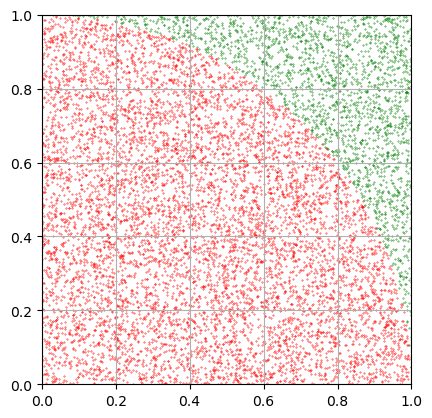

In [38]:
# Draw Nsamp points (xi, yi) from the box [0,1]x[0,1]
Nsamp = 10000
x = rng.random(size=Nsamp)
y = rng.random(size=Nsamp)

# Check which point falls within the quarter circle r=1 i.e.,
# sqrt(x^2 + y^2) <= 1. Numpy automatically does this 
# element-wise and will return a boolean array

r = np.sqrt(x**2 + y**2)
is_inside = (r <= 1)

# Taking the sum of the boolean array returns how many True
# is inside. Thus, the fraction of True's from the drawn points is:
inside_ratio = np.sum(is_inside)/Nsamp

# What is 4 times this ratio?
print(inside_ratio*4)

## Visualization
fig, ax = plt.subplots()
ax.scatter(x[is_inside], y[is_inside], s=0.1, c="red")
ax.scatter(x[~is_inside], y[~is_inside], s=0.1, c="green")
ax.set(xlim=[0,1], ylim=[0,1], aspect="equal")
ax.grid(True)

Let's try a more fun integral
$I = \int_\infty^\infty \frac{e^{-x^2}}{\sqrt{x^2 + 1}}dx$
> From Wolfram Alpha ... $I\approx 1.52411$

What does it look like?

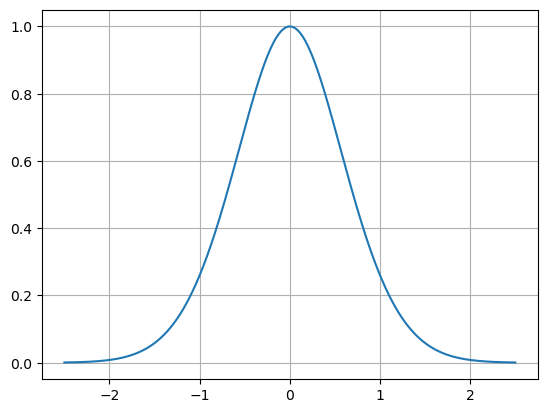

In [39]:
x = np.linspace(-2.5, 2.5, 1000)
curve = np.exp(-x**2)/np.sqrt(x**2 + 1)

fig, ax = plt.subplots()
ax.plot(x, curve)
ax.grid(True)

If we naively apply the principle above, we just need to draw numbers $x_i$ from $(-\infty, \infty)$, draw another number $y_i$ from $[0, \infty)$, then check if $y_i$ is underneath $f(x_i)$. The ratio of points $(x_i, y_i)$ that fall within the curve will give the area under the curve as a proportion of the rectangle covering it.
- Would drawing from `rng.uniform` from $(-\infty, \infty)$ make sense?
- Do I really have to draw points $y_i$ above 1 if the height of the curve doesn't go beyond that anyway?
- Bulk of the area falls within $−1<x<1$ where the points are likely to fall inside. Beyond that, getting underneath the curve is very unlikely, *but still contributes to the area.*

Consider the form:
$$I=\int_{-\infty}^\infty f(x) p(x) dx $$ where with random variable $X$ with probability distribution $p(x)$, we're finding the expectation $\langle f(x) \rangle_X$.

In [40]:
# Draw from N(0, 1/sqrt(2)) ~ (1/sqrt(pi))*exp(-x^(-2))
x = rng.normal(0, 1/np.sqrt(2), size=100000)
# Take the average. f has to cancel the (1/sqrt(pi)) from p(x)
expect = np.mean(np.sqrt(np.pi)/(np.sqrt(1 + x**2)))
print(expect)


my_int = lambda x: np.exp(-x**2)/np.sqrt(1 + x**2)
quad_out, err = integrate.quad(my_int, -np.inf, np.inf)
print(quad_out)

1.5242931690618449
1.5241093857739092


But what if I only want to integrate over $[1,5]$?

Look at Eq. 7.192 and Eq. 7.211 in Gezerlis (p. 543). First term is the one we did above

In [41]:
N = 100000

x = rng.normal(0, 1/np.sqrt(2), size=N)
# x = x[(x >= 1) * (x <= 5)]

fs = np.sqrt(np.pi)/(np.sqrt(1 + x**2))
fbar = np.sum(fs)/N
fsq = np.sum(fs**2)/N
varfbar = (fsq - fbar**2)/(N-1)

# bmina = 5 - 1


my_int = lambda x: np.exp(-x**2)/np.sqrt(1 + x**2)
quad_out, err = integrate.quad(my_int, 1, 5)
print(quad_out)

0.08520888517416615


In [42]:
x = np.linspace(1e-6, 10, 100)

p_x = np.exp(-x)

cdf_px = np.cumsum(p_x)/np.sum(p_x)
inv_cdf = interpolate.interp1d(cdf_px, x)

draw_nums = rng.uniform(min(cdf_px), max(cdf_px), 100000)

exp_draws = inv_cdf(draw_nums)

o = exp_draws #I'm lazy
vals = (o + o**2)/np.sqrt(o)

np.mean(vals)


# plt.hist(exp_draws, bins=100)
# plt.show()

2.219282986179471

9.42477796076938

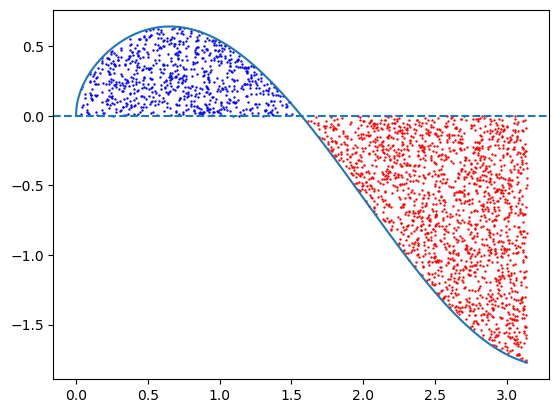

In [44]:
x = np.linspace(0, np.pi, 1000)

integrand = lambda x: np.cos(x) * np.sqrt(x)
plt.plot(x, integrand(x))


Nsamp = 10000
x_i = rng.uniform(0, np.pi, Nsamp)
y_i = rng.uniform(-2, 1, Nsamp) # arbitrary, where I think the curve is still inside

is_inside = y_i < integrand(x_i)
is_pos = y_i > 0
is_neg = y_i < 0

plt.scatter(x_i[is_inside*is_pos], y_i[is_inside*is_pos], c="blue", s=0.5)
plt.scatter(x_i[~is_inside*is_neg], y_i[~is_inside*is_neg], c="red", s=0.5)

plt.axhline(0, linestyle="--")

total_area = (np.pi - 0) * (1 - (-2))

## Q: Which contributes positive/negative area? How many dots overall?
## what is the overall are of the uniform distribution where the 
## points were drawn from.
total_area